# Credit and funding research extension — 17 October 2026

This is an isolated amendment to the portfolio research repository. Both portfolio notebooks, frozen protocols, source pins and paper journal remain unchanged. It adds a daily disclosure/credit assessment and a separate monthly cash-funding stress engine. All calculation functions are embedded below.

**Evidence:** verified public disclosures, a small current-vintage broad-credit snapshot, and explicitly synthetic software scenarios. Issuer bond history, matched credit peers and a usable monthly company cash forecast are unavailable. No first-warning date, default probability, improved trading return or live permission is claimed. The module is not connected to EMA/VWAP, broker orders or portfolio allocations.

Date-only disclosures enter at the following local midnight as a conservative research convention. This is not evidence of actual historical feed arrival. No June financial statements enter a June decision when publication was later. All monetary calculations below use USD millions.

**Review corrections, 17 October 2026:** select the newest available accounting period before its latest revision; require issuer, sector and broad-credit assessments to share the decision timestamp and correct type; draw eligible facilities in earliest-expiry order with an ID tie-break; separate nominal unused capacity from currently drawable capacity; reject missing facility dates and nonnumeric cash inputs. These repairs are recorded in the source manifest with the preceding artifact hashes. The original rule thresholds and source observations are unchanged. Earliest-expiry draw order is a liquidity convention, not a globally optimal financing policy.


In [1]:
from pathlib import Path
import json, hashlib
import pandas as pd
import numpy as np
from IPython.display import display
from review_checks import verify_review_snapshot
print(verify_review_snapshot())
manifest=json.loads(Path('data/credit_funding_20261017/manifest.json').read_text(encoding='utf-8'))
for name, expected in manifest['file_sha256'].items():
    if hashlib.sha256(Path(name).read_bytes()).hexdigest()!=expected:
        raise ValueError('Credit research input/source changed: '+name)
document=json.loads(Path('data/credit_funding_20261017/source_observations.json').read_text(encoding='utf-8'))
spec=json.loads(Path('research/credit_funding/specification.json').read_text(encoding='utf-8'))
ASOF=document['retrieved_at_utc']
print('Research as-of:',ASOF,'| user-facing audit date:',document['source_audit_date_sgt'])


{'baseline_sha256': 'a1924728765f10d91d7620054e5d2e604e1b3df3f47b872c74fefce41c85d244', 'parent_protocol_sha256': '97226bad70fc261537536322b6450d36379c8a389b99bd52642f58a3cea59bf2', 'paper_protocol_sha256': '6cad006a15f77ffd19fa5147e3262f1693b8edf68f13a20de980e8653a05a536', 'journal_head_sha256': '5808c1f3bcfb7c85202cd42ab552675f6605f3d2c4d9a1bb0d27b80a16cfdc66', 'journal_entries': 1, 'status': 'VERIFIED_DATED_SNAPSHOT'}
Research as-of: 2026-10-16T23:20:49Z | user-facing audit date: 2026-10-17


## Calculation implementation

Independent rules, explicit availability and cash accounting. Thresholds are untuned research assumptions. Missing issuer inputs remain UNKNOWN.

In [2]:
"""Daily research assessments and monthly cash stress; never a trading control."""
from dataclasses import dataclass
import math
import numpy as np
import pandas as pd


def aware(value):
    timestamp = pd.Timestamp(value)
    if pd.isna(timestamp) or timestamp.tzinfo is None:
        raise ValueError('Explicit timezone-aware timestamp required.')
    return timestamp.tz_convert('UTC')


def number(value, name, minimum=None):
    if isinstance(value, (bool, np.bool_, str)) or value is None:
        raise ValueError(f'{name} must be a finite number.')
    result = float(value)
    if not math.isfinite(result) or (minimum is not None and result < minimum):
        raise ValueError(f'Invalid {name}.')
    return result


def eligible_records(records, asof):
    now = aware(asof)
    result = []
    for record in records:
        available = aware(record['eligible_at'])
        if not record.get('source_url') or not record.get('availability_basis'):
            raise ValueError('Source and availability basis required.')
        published = pd.Timestamp(record['published_on']).date()
        if available.tz_convert('America/New_York').date() < published:
            raise ValueError('Availability precedes publication.')
        if available <= now:
            result.append(record)
    return sorted(result, key=lambda r: aware(r['eligible_at']))


def funding_assessment(document, asof, max_age_days=180):
    now = aware(asof)
    if number(max_age_days,'fundamental maximum age',0) == 0:
        raise ValueError('Positive fundamental maximum age required.')
    if len({r['issuer'] for key in ['fundamentals','financing_events'] for r in document[key]}) != 1:
        raise ValueError('Assess one issuer at a time; do not mix company disclosures.')
    financials = eligible_records(document['fundamentals'], now)
    events = eligible_records(document['financing_events'], now)
    result = {'funding_state': 'UNKNOWN', 'historical_investment_gap_usdm': None,
              'financing_access': 'NO_QUALIFIED_EVENT', 'renewal_exposure': False,
              'current_usable_cash': None, 'forward_funding_gap': None,
              'forward_model_status': 'UNKNOWN_REQUIRES_POOL_SPECIFIC_MONTHLY_INPUTS',
              'default_probability': None, 'asof_utc': now.isoformat()}
    if financials:
        # A late amendment to an old period must not supersede newer accounts.
        # For the same period, use the latest version actually available as of now.
        latest = max(financials,key=lambda r:(pd.Timestamp(r['period_end']),aware(r['eligible_at'])))
        age = (now.tz_convert('America/New_York').date()-pd.Timestamp(latest['period_end']).date()).days
        if age < 0:
            raise ValueError('Financial period ends after decision.')
        result['fundamental_age_days'] = age
        if age <= max_age_days:
            gap = number(latest['cash_capex_h1'], 'capex', 0)-number(latest['operating_cash_flow_h1'], 'OCF')
            result['historical_investment_gap_usdm'] = gap
            result['funding_state'] = 'FUNDING_VULNERABILITY' if gap > 0 and number(latest['debt_principal'], 'debt', 0) > 0 else 'NO_RULE_FLAG'
        else:
            result['reason'] = 'Stale financial period; current condition unknown.'
    recent = [e for e in events if (now-aware(e['eligible_at'])).total_seconds() <= max_age_days*86400]
    result['event_ids'] = [e['event_id'] for e in recent]
    if any(e['kind'] == 'completed_financing' for e in recent):
        result['financing_access'] = 'RECENT_COMPLETED_FINANCING'
    elif any(e['kind'] == 'committed_facility' for e in recent):
        result['financing_access'] = 'COMMITTED_FACILITY_ANNOUNCED'
    result['renewal_exposure'] = any(e.get('loan_term_years', 0) > e.get('average_contract_years', float('inf')) for e in recent)
    if result['renewal_exposure']:
        result['funding_state'] = 'FUNDING_VULNERABILITY'
    return result


def credit_assessment(rows, asof, *, kind='issuer', history=20, persistence=3,
                      widening_bp=100., relative_bp=50., max_age_days=4, max_gap_days=4):
    """Require comparable OAS observations and a fixed prior reference window.

    Input rows describe one fixed issuer curve/peer basket, or one broad index.
    Repeated prints cannot masquerade as persistent days. No yield-as-OAS fallback.
    """
    if (kind not in {'issuer', 'broad'} or isinstance(history,bool) or isinstance(persistence,bool)
            or not isinstance(history,(int,np.integer)) or not isinstance(persistence,(int,np.integer))
            or history < 2 or persistence < 1):
        raise ValueError('Invalid credit policy.')
    for value,name in [(widening_bp,'widening threshold'),(relative_bp,'relative threshold'),
                       (max_age_days,'maximum age'),(max_gap_days,'maximum gap')]:
        if number(value,name,0) == 0:
            raise ValueError('Positive credit thresholds and freshness limits required.')
    now = aware(asof)
    def result(**fields):
        return dict(asof_utc=now.isoformat(),kind=kind,**fields)
    available = []
    for row in rows:
        released, observed = aware(row['eligible_at']), aware(row['observed_at'])
        if released < observed:
            raise ValueError('Credit observation available before it existed.')
        if released > now:
            continue
        if row.get('qualified') is not True or row.get('spread_kind') != 'OAS_BP' or not row.get('comparison_id'):
            return result(state='UNKNOWN',reason='Unqualified or incompatible spread measurement.')
        number(row['spread_bp'], 'spread')
        if kind == 'issuer':
            number(row['peer_spread_bp'], 'peer spread')
        available.append(row)
    available.sort(key=lambda r: aware(r['observed_at']))
    dates = [aware(r['observed_at']).tz_convert('America/New_York').date() for r in available]
    if len(dates) != len(set(dates)):
        raise ValueError('One qualified aggregate per observation day required.')
    if len(available) < history+persistence:
        return result(state='UNKNOWN',reason='Insufficient qualified prior history and persistence.',observations=len(available))
    selected = available[-history-persistence:]
    if len({r['comparison_id'] for r in selected}) != 1:
        return result(state='UNKNOWN',reason='Instrument/peer basket changed.')
    ages = [(aware(b['observed_at'])-aware(a['observed_at'])).total_seconds()/86400 for a,b in zip(selected, selected[1:])]
    if max(ages) > max_gap_days or (now-aware(selected[-1]['observed_at'])).total_seconds() > max_age_days*86400:
        return result(state='UNKNOWN',reason='Stale or discontinuous credit observations.')
    reference, recent = selected[:history], selected[history:]
    base = float(np.median([r['spread_bp'] for r in reference]))
    changes = [r['spread_bp']-base for r in recent]
    relative = None
    stress = all(value >= widening_bp for value in changes)
    if kind == 'issuer':
        residual = float(np.median([r['spread_bp']-r['peer_spread_bp'] for r in reference]))
        relative = [r['spread_bp']-r['peer_spread_bp']-residual for r in recent]
        stress = stress and all(value >= relative_bp for value in relative)
    return result(state=('ACTIVE_ISSUER_STRESS' if kind == 'issuer' else 'BROAD_CREDIT_STRESS') if stress else 'NO_RULE_FLAG',
            widening_bp=changes,peer_relative_bp=relative,reference_end=reference[-1]['observed_at'],
            persistence_observations=persistence,
            reason='Untuned research threshold; not a probability or trading instruction.')


def assessment_state(assessment, now, kind):
    """Do not reuse stale, future, untyped or unstamped assessment objects."""
    allowed={'UNKNOWN','NO_RULE_FLAG','ACTIVE_ISSUER_STRESS' if kind=='issuer' else 'BROAD_CREDIT_STRESS'}
    if (not isinstance(assessment,dict) or assessment.get('kind')!=kind
            or not assessment.get('asof_utc') or assessment.get('state') not in allowed):
        return 'UNKNOWN'
    return assessment['state'] if aware(assessment['asof_utc'])==aware(now) else 'UNKNOWN'


def combine_assessments(funding, issuer, broad, sector_states=None, equity_breadth=None,
                        sector_min=3, sector_fraction=.5, weak_fraction=.6):
    """Independent dimensions; issuer distress never implies a bearish index."""
    now=aware(funding['asof_utc'])
    if isinstance(sector_min,bool) or not isinstance(sector_min,(int,np.integer)) or sector_min<1:
        raise ValueError('Positive integer sector coverage required.')
    for value in [sector_fraction,weak_fraction]:
        if not 0<number(value,'breadth threshold')<=1:
            raise ValueError('Breadth thresholds must be in (0,1].')
    issuer_state=assessment_state(issuer,now,'issuer')
    credit_state=assessment_state(broad,now,'broad')
    sector_states = sector_states or {}
    states=[assessment_state(s,now,'issuer') for s in sector_states.values()]
    known = [s for s in states if s in {'ACTIVE_ISSUER_STRESS','NO_RULE_FLAG'}]
    sector = 'UNKNOWN'
    if len(known) == len(sector_states) and len(known) >= sector_min:
        sector = 'SECTOR_STRESS' if known.count('ACTIVE_ISSUER_STRESS')/len(known) >= sector_fraction else 'NO_RULE_FLAG'
    broad_state = 'UNKNOWN'
    # Breadth must come from a separately qualified same-decision-time input.
    if equity_breadth is not None:
        observed, released = aware(equity_breadth['observed_at']), aware(equity_breadth['eligible_at'])
        if released < observed:
            raise ValueError('Breadth available before observation.')
        qualified = (equity_breadth.get('qualified') is True and observed <= released <= now
                     and (now-observed).total_seconds() <= 86400)
        breadth = number(equity_breadth['weak_fraction'], 'qualified equity breadth', 0)
        if breadth > 1:
            raise ValueError('Breadth must be a fraction.')
        if qualified and credit_state != 'UNKNOWN':
            broad_state = 'BROAD_MARKET_STRESS' if credit_state == 'BROAD_CREDIT_STRESS' and breadth >= weak_fraction else 'NO_RULE_FLAG'
    action = 'REVIEW_ISSUER_EXPOSURE' if issuer_state == 'ACTIVE_ISSUER_STRESS' else 'WATCH_FUNDING' if funding['funding_state'] == 'FUNDING_VULNERABILITY' else 'INSUFFICIENT_EVIDENCE' if funding['funding_state'] == 'UNKNOWN' else 'NO_RULE_FLAG'
    return {'asof_utc':now.isoformat(),'funding_state': funding['funding_state'], 'issuer_credit_state': issuer_state,
            'sector_state': sector, 'broad_market_state': broad_state, 'research_action': action,
            'credit_input_rule':'All component assessments must be typed and evaluated at the same decision timestamp.',
            'trading_permission': 'NOT_CONNECTED', 'default_probability': None}


@dataclass(frozen=True)
class FundingScenario:
    name: str = 'baseline'
    floating_rate_shock_bp: float = 0.
    refinancing_rate_shock_bp: float = 0.
    discretionary_capex_fraction: float = 1.
    committed_access_fraction: float = 1.
    collateral_capacity_fraction: float = 1.


CASH_COLUMNS = ['operating_cash_flow', 'mandatory_capex', 'discretionary_capex',
                'principal_due', 'finance_lease_principal', 'other_nonoperating_payments',
                'unhedged_floating_balance', 'refinanced_fixed_balance', 'additional_receipt_shortfall']


def funding_path(monthly, initial_cash, facilities, scenario=FundingScenario(), *,
                 cash_pool, currency='USD', units='millions', ocf_includes_interest_and_operating_leases=True):
    """One explicitly usable cash pool; missing forward schedules are not estimated.

    OCF includes baseline interest/operating leases; rate shocks are incremental.
    Floating and refinanced-fixed balances must be disjoint monthly exposures.
    No credit-line interest is inferred: include it in supplied OCF or incremental
    exposures. These are conditional cash scenarios, not a full debt pricing model.
    """
    if not cash_pool or currency != 'USD' or units != 'millions' or ocf_includes_interest_and_operating_leases is not True:
        raise ValueError('Explicit USD-million cash pool and net-OCF convention required.')
    if list(monthly.columns) != CASH_COLUMNS or not isinstance(monthly.index, pd.DatetimeIndex) or monthly.index.tz is not None:
        raise ValueError('Explicit monthly cash schema and naive month-end index required.')
    if not 1 <= len(monthly) <= 24 or not monthly.index.equals(pd.date_range(monthly.index[0], periods=len(monthly), freq='ME')):
        raise ValueError('Unique consecutive month ends required (1 to 24 months).')
    if not monthly.index.is_month_end.all() or not monthly.index.equals(monthly.index.normalize()):
        raise ValueError('Finite complete month-end forecast required.')
    monthly=monthly.apply(lambda column: column.map(lambda value:number(value,'monthly forecast')))
    if (monthly.drop(columns='operating_cash_flow') < 0).any().any():
        raise ValueError('Payments and exposure balances cannot be negative.')
    cash = number(initial_cash, 'usable initial cash', 0)
    for field in ['discretionary_capex_fraction','committed_access_fraction','collateral_capacity_fraction']:
        if not 0 <= number(getattr(scenario,field),field) <= 1:
            raise ValueError('Scenario capacity/spending fractions must be within [0,1].')
    for field in ['floating_rate_shock_bp','refinancing_rate_shock_bp']:
        number(getattr(scenario,field),field,0)
    capacities = {}
    for facility in facilities:
        key = facility['id']
        if not isinstance(key,str) or not key or key in capacities or facility['cash_pool'] != cash_pool or facility.get('qualified_drawable') is not True:
            raise ValueError('Unique, verified drawable same-pool facilities required.')
        start,end = pd.Timestamp(facility['drawable_from']),pd.Timestamp(facility['expires_on'])
        if (pd.isna(start) or pd.isna(end) or start.tzinfo is not None or end.tzinfo is not None
                or start!=start.normalize() or end!=end.normalize() or start > end):
            raise ValueError('Invalid facility availability dates.')
        capacities[key] = number(facility['capacity'], 'facility capacity', 0)*scenario.committed_access_fraction*scenario.collateral_capacity_fraction
    # Deterministic liquidity-preserving convention; not a cost-optimal treasury plan.
    facilities=sorted(facilities,key=lambda f:(pd.Timestamp(f['expires_on']),f['id']))
    rows = []
    for day,row in monthly.iterrows():
        start = day.replace(day=1)
        interest = (row.unhedged_floating_balance*scenario.floating_rate_shock_bp+row.refinanced_fixed_balance*scenario.refinancing_rate_shock_bp)/10000*day.days_in_month/365
        payments = row.mandatory_capex+row.discretionary_capex*scenario.discretionary_capex_fraction+row.principal_due+row.finance_lease_principal+row.other_nonoperating_payments+interest
        opening = cash
        cash += row.operating_cash_flow-row.additional_receipt_shortfall-payments
        draw = 0.
        # Require availability throughout the month. Intra-month timing is not modelled.
        for facility in facilities:
            if pd.Timestamp(facility['drawable_from']) <= start and pd.Timestamp(facility['expires_on']) >= day:
                amount = min(max(0.,-cash), capacities[facility['id']])
                capacities[facility['id']] -= amount
                draw += amount
                cash += amount
        rows.append({'month':day, 'opening_cash':opening, 'net_ocf_after_shortfall':row.operating_cash_flow-row.additional_receipt_shortfall,
                     'cash_payments':payments, 'incremental_interest':interest, 'committed_draw':draw,
                     'closing_cash':cash, 'unfunded_gap':max(0.,-cash),
                     'remaining_nominal_capacity':sum(capacities.values()),
                     'drawable_capacity':sum(capacities[f['id']] for f in facilities
                         if pd.Timestamp(f['drawable_from'])<=start and pd.Timestamp(f['expires_on'])>=day)})
    result = pd.DataFrame(rows).set_index('month')
    # Independent cumulative reconciliation prevents repeated counting of cash or draws.
    expected = initial_cash+(result.net_ocf_after_shortfall-result.cash_payments+result.committed_draw).cumsum()
    if not np.allclose(expected,result.closing_cash,atol=1e-10):
        raise RuntimeError('Cash accounting failed reconciliation.')
    result.attrs.update(scenario=scenario.name, cash_pool=cash_pool, currency=currency, units=units,
        peak_funding_gap=float(result.unfunded_gap.max()), evidence='Conditional monthly scenario; intra-month shortfalls may be hidden. Not a default forecast.')
    return result


## Verified disclosure case: funding dependence and financing access

The June 2026 filing reports historical financing dependence. The August loan announcement also exposes renewal risk. The September convertible financing is favourable evidence of access to capital and is retained separately; it does not establish an October cash balance.

Sources: [June 10-Q](https://www.sec.gov/Archives/edgar/data/1769628/000176962826000366/crwv-20260630.htm), [filing availability](https://www.sec.gov/Archives/edgar/data/1769628/000176962826000366/0001769628-26-000366-index.htm), [August facility](https://investors.coreweave.com/news/news-details/2026/CoreWeave-Closes-2-6-Billion-Loan-Facility-Expanding-Financing-Flexibility-for-AI-Infrastructure/default.aspx), [September financing](https://www.sec.gov/Archives/edgar/data/1769628/000176962826000432/crwv-20260917.htm).


In [3]:
funding=funding_assessment(document,ASOF,spec['fundamental_max_age_days'])
display(pd.Series(funding).to_frame('Assessment'))
timeline=pd.DataFrame([funding_assessment(document,t,spec['fundamental_max_age_days']) for t in
    ['2026-06-30T20:00:00Z','2026-08-10T20:00:00Z','2026-08-13T20:00:00Z','2026-09-21T20:00:00Z',ASOF]])
display(timeline[['asof_utc','funding_state','historical_investment_gap_usdm','financing_access','renewal_exposure']])
completed=document['financing_events'][1]
print('Net after capped calls, before offering expenses (historical transaction only):',
      completed['net_before_expenses']-completed['capped_call_cost'],'USD million')
print('This is not current cash and is not added to the June balance.')


,Assessment
funding_state,FUNDING_VULNERABILITY
historical_investment_gap_usdm,10454.0
financing_access,RECENT_COMPLETED_FINANCING
renewal_exposure,True
current_usable_cash,None
forward_funding_gap,None
forward_model_status,UNKNOWN_REQUIRES_POOL_SPECIFIC_MONTHLY_INPUTS
default_probability,None
asof_utc,2026-10-16T23:20:49+00:00
fundamental_age_days,108


,asof_utc,funding_state,historical_investment_gap_usdm,financing_access,renewal_exposure
0,2026-06-30T20:00:00+00:00,UNKNOWN,NaN,NO_QUALIFIED_EVENT,False
1,2026-08-10T20:00:00+00:00,UNKNOWN,NaN,NO_QUALIFIED_EVENT,False
2,2026-08-13T20:00:00+00:00,FUNDING_VULNERABILITY,10454.0,COMMITTED_FACILITY_ANNOUNCED,True
3,2026-09-21T20:00:00+00:00,FUNDING_VULNERABILITY,10454.0,COMMITTED_FACILITY_ANNOUNCED,True
4,2026-10-16T23:20:49+00:00,FUNDING_VULNERABILITY,10454.0,RECENT_COMPLETED_FINANCING,True


Net after capped calls, before offering expenses (historical transaction only): 3570.8 USD million
This is not current cash and is not added to the June balance.


## Credit evidence and transmission

[FRED](https://fred.stlouisfed.org/series/BAMLH0A0HYM2) reports a broad high-yield OAS increase from 3.11% to 3.23% between October 9 and 15: 12 basis points. This is not CoreWeave's bond spread. Only five current-vintage observations are retained, insufficient for the declared 20-prior-observation plus 3-observation persistence rule. Their historical release vintages are unqualified; none can enter before this retrieval.

Issuer bonds require stable instrument/peer definitions, comparable OAS units, observation and dissemination timestamps, and stale-print checks. [FINRA TRACE](https://www.finra.org/sites/default/files/TRACE_Overview.pdf) describes distinct end-of-day and historical products; no entitled issuer panel has been obtained here. A reported bond yield is not substituted for an OAS series.


In [4]:
snapshot=document['broad_credit_snapshot']
# Retain source dates as dates. Do not invent exact OAS observation/release times.
# These five descriptive values are not a qualified point-in-time credit panel.
broad=credit_assessment([],ASOF,kind='broad',history=spec['credit_history_observations'],
    persistence=spec['credit_persistence_observations'],widening_bp=spec['broad_widening_bp'],
    max_age_days=spec['credit_max_age_days'],max_gap_days=spec['credit_max_gap_days'])
issuer=credit_assessment([],ASOF,history=spec['credit_history_observations'],
    persistence=spec['credit_persistence_observations'],widening_bp=spec['issuer_widening_bp'],
    relative_bp=spec['peer_relative_widening_bp'],max_age_days=spec['credit_max_age_days'],max_gap_days=spec['credit_max_gap_days'])
combined=combine_assessments(funding,issuer,broad,sector_min=spec['sector_min_issuers'],
    sector_fraction=spec['sector_stress_fraction'],weak_fraction=spec['broad_equity_weak_fraction'])
display(pd.DataFrame(snapshot['observations']))
display(pd.Series(combined).to_frame('Research state'))
display(pd.Series(document['unavailable']).to_frame('Missing evidence'))
print('Broad credit gate:',broad,'| descriptive snapshot observations:',len(snapshot['observations']))


,date,oas_pct
0,2026-10-09,3.11
1,2026-10-12,3.11
2,2026-10-13,3.16
3,2026-10-14,3.25
4,2026-10-15,3.23


,Research state
asof_utc,2026-10-16T23:20:49+00:00
funding_state,FUNDING_VULNERABILITY
issuer_credit_state,UNKNOWN
sector_state,UNKNOWN
broad_market_state,UNKNOWN
research_action,WATCH_FUNDING
credit_input_rule,All component assessments must be typed and ev...
trading_permission,NOT_CONNECTED
default_probability,None


,Missing evidence
issuer_bond_panel,"Qualified instrument-level price/OAS history, ..."
matched_credit_peers,"Comparable maturity, seniority, currency and c..."
monthly_cash_forecast,"Pool-specific receipts, mandatory commitments,..."
floating_and_hedge_schedule,"Monthly unhedged balances, reset dates and hed..."
sector_breadth,No qualified cross-issuer credit panel
equity_transmission,No matched daily equity-breadth observations i...
historical_vintages,Broad credit download does not establish histo...


Broad credit gate: {'asof_utc': '2026-10-16T23:20:49+00:00', 'kind': 'broad', 'state': 'UNKNOWN', 'reason': 'Insufficient qualified prior history and persistence.', 'observations': 0} | descriptive snapshot observations: 5


## Monthly cash stress engine — synthetic arithmetic scenarios

The following fictional cash pool demonstrates accounting, not a CoreWeave forecast. It uses net operating cash flow after baseline interest and operating leases, mandatory/discretionary capital spending, principal, finance-lease principal and additional receipt shortfalls. Only unhedged floating and refinanced-fixed balances receive incremental rate shocks; unchanged fixed coupons do not reprice.

Only verified committed capacity in the same cash pool can be drawn, and capacity is consumed once. Facilities must cover the whole model month. Monthly timing can hide intra-month deficits. Facility-interest assumptions must be included in supplied OCF or exposure balances. Forecasts must be supplied separately for non-transferable subsidiary pools; no blanket aggregation is allowed. Delayed receipts must include any later recovery explicitly. All scenario assumptions are exposed below.


,operating_cash_flow,mandatory_capex,discretionary_capex,principal_due,finance_lease_principal,other_nonoperating_payments,unhedged_floating_balance,refinanced_fixed_balance,additional_receipt_shortfall
2026-11-30,30.0,35.0,10.0,0,2.0,0.0,200.0,0.0,0.0
2026-12-31,30.0,35.0,10.0,0,2.0,0.0,200.0,0.0,0.0
2027-01-31,30.0,35.0,10.0,30,2.0,0.0,200.0,0.0,0.0
2027-02-28,30.0,35.0,10.0,0,2.0,0.0,200.0,0.0,0.0
2027-03-31,30.0,35.0,10.0,0,2.0,0.0,200.0,0.0,0.0
2027-04-30,30.0,35.0,10.0,30,2.0,0.0,200.0,0.0,0.0
2027-05-31,30.0,35.0,10.0,0,2.0,0.0,200.0,100.0,0.0
2027-06-30,30.0,35.0,10.0,0,2.0,0.0,200.0,100.0,0.0
2027-07-31,30.0,35.0,10.0,30,2.0,0.0,200.0,100.0,0.0
2027-08-31,30.0,35.0,10.0,0,2.0,0.0,200.0,100.0,0.0


,name,floating_rate_shock_bp,refinancing_rate_shock_bp,discretionary_capex_fraction,committed_access_fraction,collateral_capacity_fraction
0,base,0.0,0.0,1.0,1.0,1.0
1,rates_plus_300bp,300.0,300.0,1.0,1.0,1.0
2,no_further_draws,0.0,0.0,1.0,0.0,1.0
3,collateral_capacity_halved,0.0,0.0,1.0,1.0,0.5
4,defer_discretionary_capex,0.0,0.0,0.0,1.0,1.0
5,receipt_delay,0.0,0.0,1.0,1.0,1.0
6,weaker_renewals,0.0,0.0,1.0,1.0,1.0


,peak_gap,ending_cash,total_draw,incremental_interest
scenario,,,,
base,44.000000,-44.000000,180.0,0.000000
rates_plus_300bp,51.512329,-51.512329,180.0,7.512329
no_further_draws,224.000000,-224.000000,0.0,0.000000
collateral_capacity_halved,134.000000,-134.000000,90.0,0.000000
defer_discretionary_capex,0.000000,0.000000,104.0,0.000000
receipt_delay,44.000000,-44.000000,180.0,0.000000
weaker_renewals,134.000000,-134.000000,180.0,0.000000


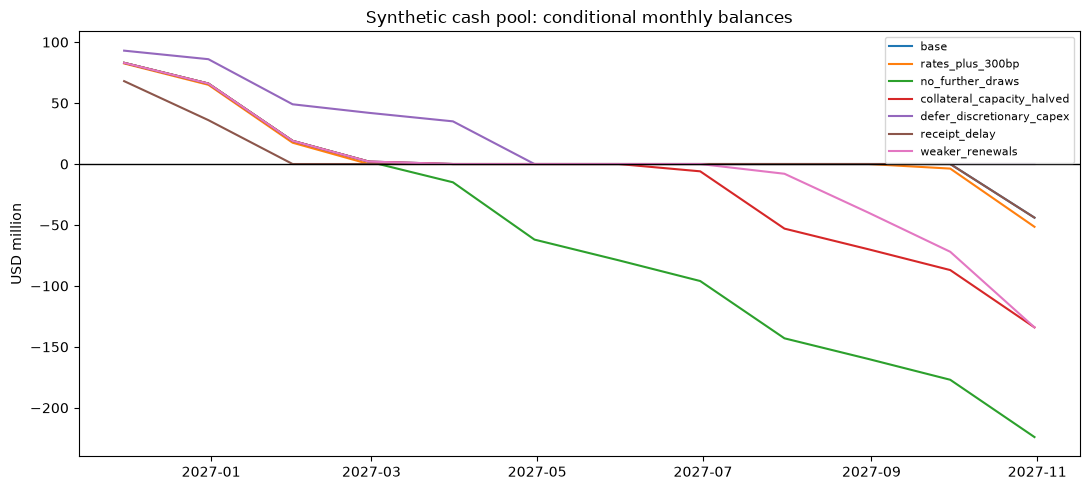

In [5]:
months=pd.date_range('2026-11-30',periods=12,freq='ME')
synthetic=pd.DataFrame(0.,index=months,columns=CASH_COLUMNS)
synthetic['operating_cash_flow']=30.
synthetic['mandatory_capex']=35.
synthetic['discretionary_capex']=10.
synthetic['principal_due']=[0,0,30,0,0,30,0,0,30,0,0,30]
synthetic['finance_lease_principal']=2.
synthetic['unhedged_floating_balance']=200.
synthetic['refinanced_fixed_balance']=[0.]*6+[100.]*6
facility=dict(id='fictional_committed_line',cash_pool='FICTIONAL_POOL',capacity=180.,qualified_drawable=True,
    drawable_from='2026-11-01',expires_on='2027-10-31')
scenarios=[FundingScenario('base'),FundingScenario('rates_plus_300bp',floating_rate_shock_bp=300,refinancing_rate_shock_bp=300),
    FundingScenario('no_further_draws',committed_access_fraction=0),FundingScenario('collateral_capacity_halved',collateral_capacity_fraction=.5),
    FundingScenario('defer_discretionary_capex',discretionary_capex_fraction=0),FundingScenario('receipt_delay'),FundingScenario('weaker_renewals')]
paths={}
for scenario in scenarios:
    forecast=synthetic.copy()
    if scenario.name=='receipt_delay':
        forecast.loc[months[:3],'additional_receipt_shortfall']=15.
        forecast.loc[months[3:6],'operating_cash_flow']+=15.
    if scenario.name=='weaker_renewals':forecast.loc[months[6:],'additional_receipt_shortfall']=15.
    paths[scenario.name]=funding_path(forecast,100.,[facility],scenario,cash_pool='FICTIONAL_POOL')
summary=pd.DataFrame([dict(scenario=name,peak_gap=path.attrs['peak_funding_gap'],ending_cash=path.closing_cash.iloc[-1],
    total_draw=path.committed_draw.sum(),incremental_interest=path.incremental_interest.sum()) for name,path in paths.items()]).set_index('scenario')
display(synthetic)
display(pd.DataFrame([s.__dict__ for s in scenarios]))
display(summary)
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(11,5))
for name,path in paths.items():ax.plot(path.index,path.closing_cash,label=name)
ax.axhline(0,color='black',linewidth=1)
ax.set(title='Synthetic cash pool: conditional monthly balances',ylabel='USD million');ax.legend(fontsize=8)
plt.tight_layout();plt.show()


## Research interpretation and next work

The verified case supports a funding-vulnerability watch and also records successful financing. Active issuer stress, sector stress, broad-market transmission and a forward company funding gap remain unknown with the qualified inputs here. A high funding need does not establish default, and an issuer warning does not establish a bearish SPY signal.

The three-way replay is explicitly **not evaluated**: price-only versus broad-credit-enriched versus issuer-enriched models need matched decision times, historical availability vintages, issuer/peer bond panels and a fixed exposure policy. Report warning lead, false alarms, avoided losses and missed gains after costs on untouched issuer/period holdouts. The known CoreWeave episode can only be a retrospective case study. Adding an HMM before acquiring these inputs would not fill the evidence gap.

These synthetic scenarios validate accounting behaviour only. Neither their cash gaps nor the rule thresholds are CoreWeave forecasts. No strategy, order, shadow process or scheduler is activated.


In [6]:
results={'asof_utc':ASOF,'funding':funding,'combined':combined,'broad_credit':broad,
    'comparison_status':'NOT_EVALUATED_MISSING_QUALIFIED_HISTORY_AND_EXPOSURE_POLICY',
    'synthetic_scenarios':summary.reset_index().to_dict('records')}
print('Freeze verification after research:',verify_review_snapshot()['status'])


Freeze verification after research: VERIFIED_DATED_SNAPSHOT
